# Ridge Trace Analysis

## Introduction

Ridge Regression introduces an L2 regularization penalty to the Ordinary Least Squares (OLS) objective function. The strength of this penalty is controlled by the regularization parameter λ (lambda).

The choice of λ influences the magnitude of the estimated regression coefficients. As λ increases, the coefficients are generally pushed towards zero, reducing their sensitivity to multicollinearity and potentially improving numerical stability.

The purpose of this experiment is to study the behaviour of Ridge Regression coefficients over a range of regularization parameter values using a Ridge Trace plot.

The objectives are:

- Investigate the effect of λ on regression coefficient estimates.
- Visualize coefficient shrinkage using a Ridge Trace plot.
- Examine the overall coefficient L2 norm as λ changes.
- Study the effect of regularization on the condition number of the system matrix.
- Compare the Ridge coefficient estimates with the unregularized OLS estimates.
- Generate numerical results that can support the selection of λ in the subsequent cross-validation experiment.

The optimal regularization parameter is not determined in this experiment. It will be selected using k-fold cross-validation in the next experiment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

np.set_printoptions(precision=6, suppress=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")

sns.set_theme(style="whitegrid")

In [2]:
results = Path("../../results/implementation")

figures = results / "figures"
tables = results / "tables"

In [3]:
df = pd.read_csv("../../data/processed/real_estate_data_updated.csv")

df.head()

,X1 transaction year,X1 transaction month,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,2012,December,32.000000,84.878820,10,24.982980,121.540240,37.900000
1,2012,December,19.500000,306.594700,9,24.980340,121.539510,42.200000
2,2013,August,13.300000,561.984500,5,24.987460,121.543910,47.300000
3,2013,July,13.300000,561.984500,5,24.987460,121.543910,54.800000
4,2012,November,5.000000,390.568400,5,24.979370,121.542450,43.100000


In [4]:
numerical_features = [
    "X2 house age",
    "X3 distance to the nearest MRT station",
    "X4 number of convenience stores",
    "X5 latitude",
    "X6 longitude"
]

categorical_features = [
    "X1 transaction month"
]

target_column = "Y house price of unit area"

X_numerical = df[numerical_features].copy()

X_categorical = pd.get_dummies(
    df[categorical_features],
    drop_first=True,
    dtype=float
)

X = pd.concat(
    [X_numerical, X_categorical],
    axis=1
)

y = df[target_column].to_numpy(dtype=float)

feature_names = X.columns.tolist()

X = X.to_numpy(dtype=float)

print("Predictor matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Number of predictors:", len(feature_names))

Predictor matrix shape: (414, 16)
Target vector shape: (414,)
Number of predictors: 16


In [5]:
# standardized predictors

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0, ddof=0)

if np.any(X_std == 0):
    raise ValueError("A predictor has zero variance.")

X_standardized = (X - X_mean) / X_std

x_design = np.column_stack([
    np.ones(X_standardized.shape[0]),
    X_standardized
])

design_feature_names = ["Intercept"] + feature_names

print("Standardization completed.")
print("Standardized design matrix shape:", x_design.shape)

print("\nMeans:")
print(np.round(X_standardized.mean(axis=0), 6))

print("\nStandard deviations:")
print(np.round(X_standardized.std(axis=0), 6))

Standardization completed.
Standardized design matrix shape: (414, 17)

Means:
[-0. -0. -0.  0. -0. -0. -0. -0.  0.  0.  0.  0. -0. -0.  0.  0.]

Standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Ridge Trace Formulation

The Ridge Regression objective function is:

\[
J(\beta)=
\|y-X\beta\|_2^2+
\lambda\|\beta\|_2^2
\]

The corresponding estimator is:

\[
\hat{\beta}_{ridge}
=
(X^TX+\lambda I)^{-1}X^Ty
\]

For this experiment, the predictor variables are standardized and the intercept is excluded from regularization.

Therefore, the estimator becomes:

\[
\hat{\beta}_{ridge}
=
(X_s^TX_s+\lambda P)^{-1}X_s^Ty
\]

where \(X_s\) represents the standardized design matrix and \(P\) is a penalty matrix whose intercept entry is zero.

A Ridge Trace plot displays the estimated regression coefficients against different values of λ.

The plot helps examine the rate of coefficient shrinkage and the sensitivity of the estimates to the regularization parameter.

In [6]:
# construct penalty matrix

n_parameters = x_design.shape[1]

penalty_matrix = np.eye(n_parameters)

# Intercept is not penalized
penalty_matrix[0, 0] = 0.0

print("Penalty matrix shape:", penalty_matrix.shape)
print("Intercept penalty:", penalty_matrix[0, 0])

Penalty matrix shape: (17, 17)
Intercept penalty: 0.0


In [7]:
# define lambda values 

lambda_values = np.logspace(-4, 4, 200)

print("Number of lambda values:", len(lambda_values))
print("Minimum lambda:", lambda_values.min())
print("Maximum lambda:", lambda_values.max())

Number of lambda values: 200
Minimum lambda: 0.0001
Maximum lambda: 10000.0


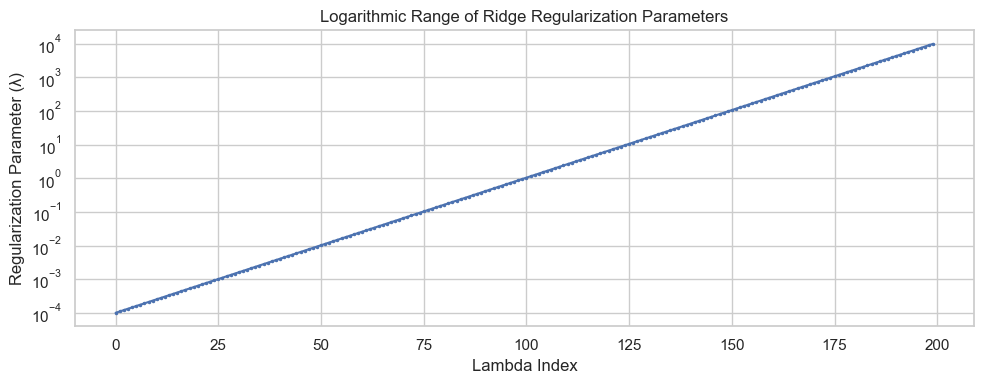

In [8]:
# visualize lambda range

plt.figure(figsize=(10, 4))

plt.plot(
    np.arange(len(lambda_values)),
    lambda_values,
    marker=".",
    markersize=3
)

plt.yscale("log")

plt.xlabel("Lambda Index")
plt.ylabel("Regularization Parameter (λ)")
plt.title("Logarithmic Range of Ridge Regularization Parameters")

plt.tight_layout()

plt.savefig(
    figures / "ridge_lambda_range.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
# implement ridge regression function

def ridge_regression(X_design, y, lambda_value, penalty_matrix):
    
    if lambda_value < 0:
        raise ValueError("Lambda must be non-negative.")

    A = (
        X_design.T @ X_design
        + lambda_value * penalty_matrix
    )

    b = X_design.T @ y

    beta = np.linalg.solve(A, b)

    return beta

In [10]:
# compute ols reference coefficients

beta_ols = np.linalg.lstsq(
    x_design,
    y,
    rcond=None
)[0]

ols_coefficients = pd.DataFrame({
    "Feature": design_feature_names,
    "OLS Coefficient": beta_ols
})

ols_coefficients

,Feature,OLS Coefficient
0,Intercept,37.980193
1,X2 house age,-3.103989
2,X3 distance to the nearest MRT station,-5.650556
3,X4 number of convenience stores,3.394340
4,X5 latitude,2.888137
5,X6 longitude,-0.186302
6,X1 transaction month_August,0.649505
7,X1 transaction month_December,-0.870451
8,X1 transaction month_February,0.236571
9,X1 transaction month_January,-0.222263


In [11]:
# compute ridge coefficients for all lambda

ridge_coefficients = []

for lambda_value in lambda_values:

    beta = ridge_regression(
        x_design,
        y,
        lambda_value,
        penalty_matrix
    )

    ridge_coefficients.append(beta)

ridge_coefficients = np.asarray(ridge_coefficients)

print("Ridge coefficient path generated.")
print("Coefficient matrix shape:", ridge_coefficients.shape)

Ridge coefficient path generated.
Coefficient matrix shape: (200, 17)


In [12]:
# create coefficient path dataframe

coefficient_path = pd.DataFrame(
    ridge_coefficients,
    columns=design_feature_names
)

coefficient_path.insert(
    0,
    "Lambda",
    lambda_values
)

coefficient_path.head()

,Lambda,Intercept,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,X1 transaction month_August,X1 transaction month_December,X1 transaction month_February,X1 transaction month_January,X1 transaction month_July,X1 transaction month_June,X1 transaction month_March,X1 transaction month_May,X1 transaction month_November,X1 transaction month_October,X1 transaction month_September
0,0.000100,37.980193,-3.103988,-5.650552,3.394340,2.888137,-0.186298,0.649504,-0.870451,0.236571,-0.222263,1.108895,-0.538559,-0.112088,0.552025,-0.379328,-0.680165,-0.423494
1,0.000110,37.980193,-3.103988,-5.650551,3.394340,2.888137,-0.186298,0.649504,-0.870451,0.236571,-0.222263,1.108895,-0.538559,-0.112088,0.552025,-0.379328,-0.680165,-0.423494
2,0.000120,37.980193,-3.103988,-5.650551,3.394340,2.888137,-0.186298,0.649504,-0.870451,0.236571,-0.222263,1.108895,-0.538559,-0.112088,0.552025,-0.379328,-0.680165,-0.423494
3,0.000132,37.980193,-3.103988,-5.650550,3.394340,2.888137,-0.186297,0.649504,-0.870451,0.236571,-0.222263,1.108895,-0.538559,-0.112088,0.552025,-0.379328,-0.680165,-0.423494
4,0.000145,37.980193,-3.103988,-5.650550,3.394340,2.888137,-0.186297,0.649504,-0.870451,0.236571,-0.222263,1.108895,-0.538559,-0.112088,0.552025,-0.379328,-0.680165,-0.423494


In [13]:
# inspect coefficient behaviour

selected_indices = [
    0,
    25,
    50,
    75,
    100,
    125,
    150,
    175,
    199
]

selected_lambda_comparison = coefficient_path.iloc[
    selected_indices
].copy()

selected_lambda_comparison

,Lambda,Intercept,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,X1 transaction month_August,X1 transaction month_December,X1 transaction month_February,X1 transaction month_January,X1 transaction month_July,X1 transaction month_June,X1 transaction month_March,X1 transaction month_May,X1 transaction month_November,X1 transaction month_October,X1 transaction month_September
0,0.000100,37.980193,-3.103988,-5.650552,3.394340,2.888137,-0.186298,0.649504,-0.870451,0.236571,-0.222263,1.108895,-0.538559,-0.112088,0.552025,-0.379328,-0.680165,-0.423494
25,0.001012,37.980193,-3.103981,-5.650509,3.394341,2.888140,-0.186265,0.649501,-0.870450,0.236572,-0.222268,1.108891,-0.538558,-0.112088,0.552023,-0.379327,-0.680164,-0.423492
50,0.010234,37.980193,-3.103908,-5.650074,3.394349,2.888173,-0.185930,0.649467,-0.870436,0.236579,-0.222312,1.108844,-0.538547,-0.112083,0.552006,-0.379312,-0.680157,-0.423473
75,0.103532,37.980193,-3.103171,-5.645687,3.394428,2.888506,-0.182547,0.649123,-0.870298,0.236651,-0.222766,1.108373,-0.538436,-0.112030,0.551835,-0.379161,-0.680089,-0.423279
100,1.047371,37.980193,-3.095727,-5.602049,3.395116,2.891734,-0.148879,0.645700,-0.868864,0.237382,-0.227260,1.103690,-0.537262,-0.111477,0.550142,-0.377626,-0.679367,-0.421308
125,10.595602,37.980193,-3.021718,-5.224820,3.391912,2.912310,0.142662,0.615743,-0.852297,0.244489,-0.265083,1.062412,-0.522096,-0.104792,0.536433,-0.361584,-0.669486,-0.400896
150,107.189132,37.980193,-2.422120,-3.736882,3.084131,2.748543,1.230837,0.452813,-0.692980,0.253748,-0.402843,0.815736,-0.360928,-0.055690,0.468121,-0.256496,-0.548052,-0.257135
175,1084.365969,37.980193,-0.810285,-1.757946,1.526895,1.433946,1.211494,0.126448,-0.235291,0.147443,-0.324954,0.182226,-0.037943,0.000884,0.216816,-0.109909,-0.183025,-0.024517
199,10000.000000,37.980193,-0.114294,-0.341442,0.290526,0.277291,0.261672,0.016050,-0.031378,0.032332,-0.068823,0.007039,0.005066,0.002622,0.037589,-0.023728,-0.025389,0.004326


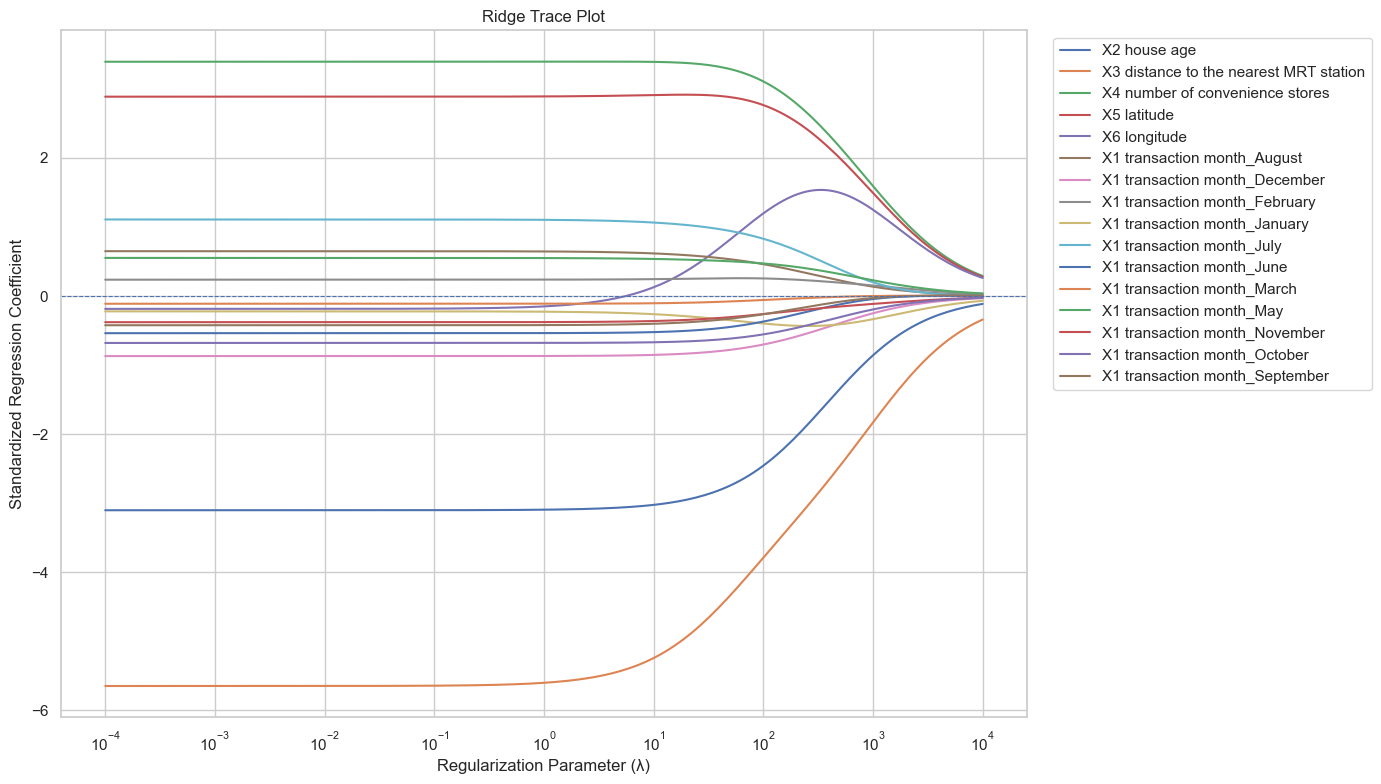

In [14]:
# ridge trace plot

plt.figure(figsize=(14, 8))

for feature in feature_names:

    plt.plot(
        lambda_values,
        coefficient_path[feature],
        label=feature,
        linewidth=1.5
    )

plt.xscale("log")

plt.xlabel("Regularization Parameter (λ)")
plt.ylabel("Standardized Regression Coefficient")
plt.title("Ridge Trace Plot")

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=0.8
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    figures / "ridge_trace_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# coefficient L2 norm

coefficient_norms = np.linalg.norm(
    ridge_coefficients[:, 1:],
    axis=1
)

coefficient_norm_data = pd.DataFrame({
    "Lambda": lambda_values,
    "Coefficient L2 Norm": coefficient_norms
})

coefficient_norm_data.head()

,Lambda,Coefficient L2 Norm
0,0.000100,8.085099
1,0.000110,8.085098
2,0.000120,8.085098
3,0.000132,8.085098
4,0.000145,8.085097


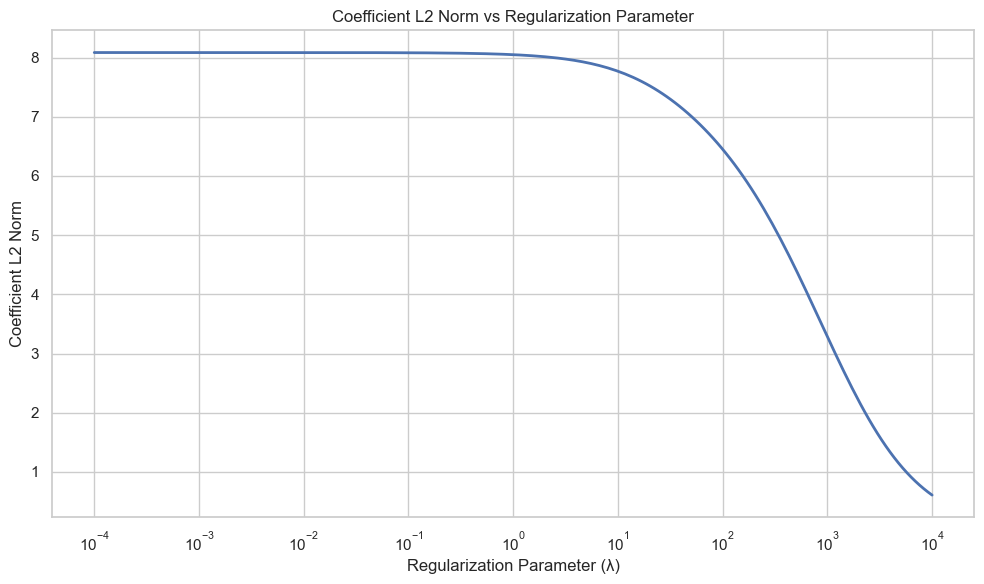

In [16]:
# plot coefficient norm

plt.figure(figsize=(10, 6))

plt.plot(
    lambda_values,
    coefficient_norms,
    linewidth=2
)

plt.xscale("log")

plt.xlabel("Regularization Parameter (λ)")
plt.ylabel("Coefficient L2 Norm")
plt.title("Coefficient L2 Norm vs Regularization Parameter")

plt.tight_layout()

plt.savefig(
    figures / "ridge_coefficient_norm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# compare ols and ridge coefficient norms

ols_coefficient_norm = np.linalg.norm(beta_ols[1:])

coefficient_norm_comparison = pd.DataFrame({
    "Method": ["OLS"] + [
        f"Ridge (λ={value:.6g})"
        for value in lambda_values
    ],
    "Lambda": [0.0] + lambda_values.tolist(),
    "Coefficient L2 Norm": [
        ols_coefficient_norm
    ] + coefficient_norms.tolist()
})

coefficient_norm_comparison.head()

,Method,Lambda,Coefficient L2 Norm
0,OLS,0.000000,8.085102
1,Ridge (λ=0.0001),0.000100,8.085099
2,Ridge (λ=0.000109699),0.000110,8.085098
3,Ridge (λ=0.000120338),0.000120,8.085098
4,Ridge (λ=0.000132009),0.000132,8.085098


In [18]:
# numerical condition number across lambda

gram_matrix = x_design.T @ x_design

condition_numbers = []

for lambda_value in lambda_values:

    ridge_system = (
        gram_matrix
        + lambda_value * penalty_matrix
    )

    condition_number = np.linalg.cond(ridge_system)

    condition_numbers.append(condition_number)

condition_numbers = np.asarray(condition_numbers)

condition_number_data = pd.DataFrame({
    "Lambda": lambda_values,
    "Condition Number": condition_numbers
})

condition_number_data.head()

,Lambda,Condition Number
0,0.000100,33.056913
1,0.000110,33.056904
2,0.000120,33.056894
3,0.000132,33.056883
4,0.000145,33.056871


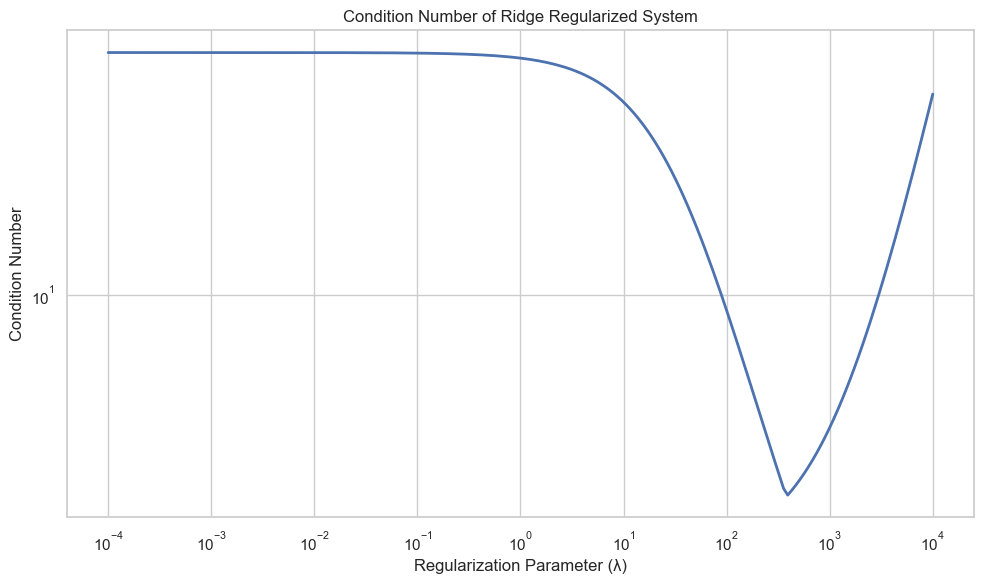

In [19]:
# plot condition number

plt.figure(figsize=(10, 6))

plt.plot(
    lambda_values,
    condition_numbers,
    linewidth=2
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Regularization Parameter (λ)")
plt.ylabel("Condition Number")
plt.title("Condition Number of Ridge Regularized System")

plt.tight_layout()

plt.savefig(
    figures / "ridge_condition_number_trace.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# evaluate training error across lambda

mse_values = []
rmse_values = []
mae_values = []
r2_values = []

for beta in ridge_coefficients:

    y_pred = x_design @ beta

    residuals = y - y_pred

    mse = np.mean(residuals ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(residuals))

    ss_res = np.sum(residuals ** 2)
    ss_total = np.sum((y - np.mean(y)) ** 2)

    r2 = 1 - ss_res / ss_total

    mse_values.append(mse)
    rmse_values.append(rmse)
    mae_values.append(mae)
    r2_values.append(r2)

training_performance = pd.DataFrame({
    "Lambda": lambda_values,
    "MSE": mse_values,
    "RMSE": rmse_values,
    "MAE": mae_values,
    "R2": r2_values
})

training_performance.head()

,Lambda,MSE,RMSE,MAE,R2
0,0.000100,74.973033,8.658697,6.013423,0.594059
1,0.000110,74.973033,8.658697,6.013423,0.594059
2,0.000120,74.973033,8.658697,6.013423,0.594059
3,0.000132,74.973033,8.658697,6.013423,0.594059
4,0.000145,74.973033,8.658697,6.013423,0.594059


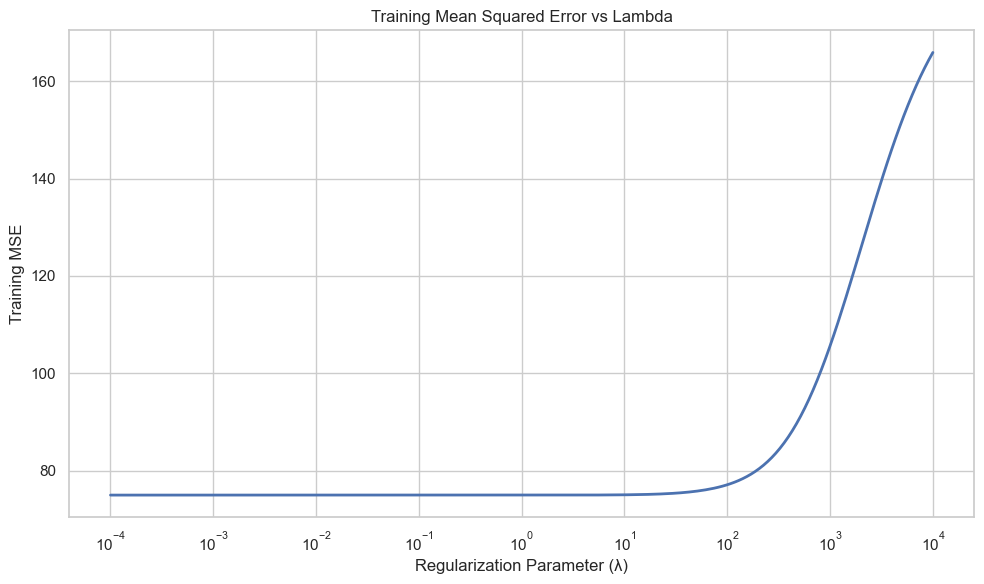

In [21]:
# plot training MSE against lambda

plt.figure(figsize=(10, 6))

plt.plot(
    lambda_values,
    training_performance["MSE"],
    linewidth=2
)

plt.xscale("log")

plt.xlabel("Regularization Parameter (λ)")
plt.ylabel("Training MSE")
plt.title("Training Mean Squared Error vs Lambda")

plt.tight_layout()

plt.savefig(
    figures / "ridge_training_mse_trace.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
# create ridge trace summary

ridge_trace_summary = pd.DataFrame({
    "Lambda": lambda_values,
    "Coefficient L2 Norm": coefficient_norms,
    "Condition Number": condition_numbers,
    "MSE": mse_values,
    "RMSE": rmse_values,
    "MAE": mae_values,
    "R2": r2_values
})

ridge_trace_summary.head()

,Lambda,Coefficient L2 Norm,Condition Number,MSE,RMSE,MAE,R2
0,0.000100,8.085099,33.056913,74.973033,8.658697,6.013423,0.594059
1,0.000110,8.085098,33.056904,74.973033,8.658697,6.013423,0.594059
2,0.000120,8.085098,33.056894,74.973033,8.658697,6.013423,0.594059
3,0.000132,8.085098,33.056883,74.973033,8.658697,6.013423,0.594059
4,0.000145,8.085097,33.056871,74.973033,8.658697,6.013423,0.594059


In [23]:
# compare selected lambda values

selected_lambda_indices = [
    0,
    25,
    50,
    75,
    100,
    125,
    150,
    175,
    199
]

selected_lambda_summary = ridge_trace_summary.iloc[
    selected_lambda_indices
].copy()

selected_lambda_summary

,Lambda,Coefficient L2 Norm,Condition Number,MSE,RMSE,MAE,R2
0,0.000100,8.085099,33.056913,74.973033,8.658697,6.013423,0.594059
25,0.001012,8.085065,33.056069,74.973033,8.658697,6.013423,0.594059
50,0.010234,8.084728,33.047538,74.973033,8.658697,6.013432,0.594059
75,0.103532,8.081320,32.961484,74.973040,8.658697,6.013515,0.594059
100,1.047371,8.047418,32.116233,74.973797,8.658741,6.014348,0.594055
125,10.595602,7.753180,25.548576,75.036417,8.662356,6.024764,0.593715
150,107.189132,6.385484,8.829865,77.310011,8.792611,6.181800,0.581405
175,1084.365969,3.150997,5.385330,107.794570,10.382416,7.766537,0.416346
199,10000.000000,0.607585,26.920678,165.887302,12.879724,10.095636,0.101803


In [24]:
# examine coefficient shrinkage 

coefficient_shrinkage = pd.DataFrame({
    "Feature": feature_names,
    "OLS Coefficient": beta_ols[1:],
    "Ridge Coefficient (Minimum Lambda)": ridge_coefficients[0, 1:],
    "Ridge Coefficient (Maximum Lambda)": ridge_coefficients[-1, 1:]
})

coefficient_shrinkage["Absolute OLS Coefficient"] = (
    np.abs(coefficient_shrinkage["OLS Coefficient"])
)

coefficient_shrinkage["Absolute Ridge Coefficient (Minimum Lambda)"] = (
    np.abs(
        coefficient_shrinkage[
            "Ridge Coefficient (Minimum Lambda)"
        ]
    )
)

coefficient_shrinkage["Absolute Ridge Coefficient (Maximum Lambda)"] = (
    np.abs(
        coefficient_shrinkage[
            "Ridge Coefficient (Maximum Lambda)"
        ]
    )
)

coefficient_shrinkage

,Feature,OLS Coefficient,Ridge Coefficient (Minimum Lambda),Ridge Coefficient (Maximum Lambda),Absolute OLS Coefficient,Absolute Ridge Coefficient (Minimum Lambda),Absolute Ridge Coefficient (Maximum Lambda)
0,X2 house age,-3.103989,-3.103988,-0.114294,3.103989,3.103988,0.114294
1,X3 distance to the nearest MRT station,-5.650556,-5.650552,-0.341442,5.650556,5.650552,0.341442
2,X4 number of convenience stores,3.394340,3.394340,0.290526,3.394340,3.394340,0.290526
3,X5 latitude,2.888137,2.888137,0.277291,2.888137,2.888137,0.277291
4,X6 longitude,-0.186302,-0.186298,0.261672,0.186302,0.186298,0.261672
5,X1 transaction month_August,0.649505,0.649504,0.016050,0.649505,0.649504,0.016050
6,X1 transaction month_December,-0.870451,-0.870451,-0.031378,0.870451,0.870451,0.031378
7,X1 transaction month_February,0.236571,0.236571,0.032332,0.236571,0.236571,0.032332
8,X1 transaction month_January,-0.222263,-0.222263,-0.068823,0.222263,0.222263,0.068823
9,X1 transaction month_July,1.108896,1.108895,0.007039,1.108896,1.108895,0.007039


In [25]:
# check coefficient norm behaviour

norm_decreases = np.all(np.diff(coefficient_norms) <= 1e-8)

print("Coefficient norm decreases monotonically:", norm_decreases)

print("OLS coefficient norm:", ols_coefficient_norm)

print("Ridge coefficient norm at minimum lambda:",
      coefficient_norms[0])

print("Ridge coefficient norm at maximum lambda:",
      coefficient_norms[-1])

Coefficient norm decreases monotonically: True
OLS coefficient norm: 8.085102388917946
Ridge coefficient norm at minimum lambda: 8.08509872914671
Ridge coefficient norm at maximum lambda: 0.6075848472362714


In [26]:
# numerical observation

minimum_lambda = lambda_values[0]
maximum_lambda = lambda_values[-1]

minimum_lambda_norm = coefficient_norms[0]
maximum_lambda_norm = coefficient_norms[-1]

minimum_lambda_condition = condition_numbers[0]
maximum_lambda_condition = condition_numbers[-1]

minimum_lambda_mse = mse_values[0]
maximum_lambda_mse = mse_values[-1]

print("RIDGE TRACE ANALYSIS – SUMMARY")

print(f"Lambda range: {minimum_lambda:.6g} to {maximum_lambda:.6g}")

print("\nCoefficient Norm:")
print(f"At minimum lambda: {minimum_lambda_norm:.6f}")
print(f"At maximum lambda: {maximum_lambda_norm:.6f}")

print("\nCondition Number:")
print(f"At minimum lambda: {minimum_lambda_condition:.6e}")
print(f"At maximum lambda: {maximum_lambda_condition:.6e}")

print("\nTraining MSE:")
print(f"At minimum lambda: {minimum_lambda_mse:.6f}")
print(f"At maximum lambda: {maximum_lambda_mse:.6f}")


RIDGE TRACE ANALYSIS – SUMMARY
Lambda range: 0.0001 to 10000

Coefficient Norm:
At minimum lambda: 8.085099
At maximum lambda: 0.607585

Condition Number:
At minimum lambda: 3.305691e+01
At maximum lambda: 2.692068e+01

Training MSE:
At minimum lambda: 74.973033
At maximum lambda: 165.887302


In [27]:
# export coefficient path

coefficient_path.to_csv(
    tables / "ridge_coefficient_path.csv",
    index=False
)

selected_lambda_comparison.to_csv(
    tables / "ridge_selected_lambda_coefficients.csv",
    index=False
)

print("Coefficient path exported successfully.")

Coefficient path exported successfully.


In [28]:
# export summary tables

coefficient_norm_data.to_csv(
    tables / "ridge_coefficient_norm_trace.csv",
    index=False
)

condition_number_data.to_csv(
    tables / "ridge_condition_number_trace.csv",
    index=False
)

training_performance.to_csv(
    tables / "ridge_training_performance_trace.csv",
    index=False
)

ridge_trace_summary.to_csv(
    tables / "ridge_trace_summary.csv",
    index=False
)

selected_lambda_summary.to_csv(
    tables / "ridge_selected_lambda_summary.csv",
    index=False
)

coefficient_shrinkage.to_csv(
    tables / "ridge_coefficient_shrinkage.csv",
    index=False
)

coefficient_norm_comparison.to_csv(
    tables / "ridge_ols_coefficient_norm_trace.csv",
    index=False
)

print("All Ridge Trace tables exported successfully.")

All Ridge Trace tables exported successfully.


## Interpretation of Ridge Trace

The Ridge Trace plot illustrates the variation in regression coefficient estimates as the regularization parameter λ increases.

At smaller values of λ, the Ridge estimates remain close to their corresponding OLS estimates.

As λ increases, the penalty term becomes more influential and the coefficient estimates are generally reduced in magnitude.

The coefficient L2 norm provides an overall measure of the magnitude of the penalized coefficients. Its behaviour helps quantify the shrinkage introduced by regularization.

The condition number of the regularized system is also examined to investigate the numerical effect of adding the penalty term.

The training error generally increases as regularization becomes stronger because the model is increasingly constrained. However, a lower training error is not necessarily an indication of better predictive performance on unseen observations.

The Ridge Trace therefore provides a useful visual and numerical understanding of the effect of regularization, but it does not independently identify the optimal value of λ.

## Conclusion

The Ridge Trace experiment examines how the estimated regression coefficients respond to different values of the regularization parameter.

The results demonstrate the relationship between regularization strength and coefficient shrinkage. The coefficient L2 norm provides a quantitative measure of this behaviour, while the condition number trace illustrates the numerical effect of regularization on the system matrix.

The experiment also highlights the trade-off between model flexibility and regularization. Although stronger regularization reduces coefficient magnitudes, it can also increase training prediction error.

Therefore, selecting λ solely on the basis of coefficient shrinkage or training error is not sufficient.

The next experiment uses k-fold cross-validation to identify a suitable regularization parameter based on validation performance.